# <u> Data Preparation and Projection Pipeline
## UK Census Visual Analytics

This notebook prepares the Census-based datasets used for the Visual Analytics coursework dashboard.
It does the following things:

- loads 2011 and 2021 England and Wales Census datasets
- cleans and standardises geographic fields, engineers percentage-based socio-economic and health features
- creates PCA and t-SNE projections
- applies Bayesian Ridge Regression for uncertainty-aware 2021 health estimation
- exports Tableau-ready CSV files.

## 1. Importing the Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import BayesianRidge
from sklearn.cluster import KMeans

## 2. Importing Raw files

The project uses five Census datasets:
- 2011 General Health
- 2011 Economic Activity
- 2011 Housing Tenure
- 2011 Qualification Levels
- 2021 General Health

In [2]:
health_2011 = pd.read_csv("uk census general health 2011.csv")
economy_2011 = pd.read_csv("uk census economic activity 2011.csv")
housing_2011 = pd.read_csv("uk census household 2011.csv")
qualification_2011 = pd.read_csv("uk census qualification 2011.csv")
health_2021 = pd.read_csv("2021_UK_health_Census_Data.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'uk census general health 2011.csv'

In [3]:
# Sanity check to confirm dataset structure and row counts.

datasets = {
    "2011 Health": health_2011,
    "2011 Economic Activity": economy_2011,
    "2011 Housing": housing_2011,
    "2011 Qualification": qualification_2011,
    "2021 Health": health_2021
}

for name, df in datasets.items():
    print(name)
    print("Shape:", df.shape)
    print()

2011 Health
Shape: (348, 10)

2011 Economic Activity
Shape: (348, 20)

2011 Housing
Shape: (348, 18)

2011 Qualification
Shape: (348, 12)

2021 Health
Shape: (1986, 5)



In [4]:
health_2011 = health_2011.rename(columns={
    "geography code": "area_code",
    "Rural Urban": "rural_urban"
})

economy_2011 = economy_2011.rename(columns={
    "geography code": "area_code",
    "Rural Urban": "rural_urban"
})

housing_2011 = housing_2011.rename(columns={
    "geography code": "area_code",
    "Rural Urban": "rural_urban"
})

qualification_2011 = qualification_2011.rename(columns={
    "geography code": "area_code",
    "Rural Urban": "rural_urban"
})

---
## 3. Merging all 2011 Datasets
The 2011 datasets were merged using common local authority identifiers (area codes) as keys. This created one local-authority-level table containing health, employment, housing and qualification information.

In [5]:
df_2011 = health_2011.merge(
    economy_2011,
    on=["date", "geography", "area_code", "rural_urban"],
    how="inner"
)

df_2011 = df_2011.merge(
    housing_2011,
    on=["date", "geography", "area_code", "rural_urban"],
    how="inner"
)

df_2011 = df_2011.merge(
    qualification_2011,
    on=["date", "geography", "area_code", "rural_urban"],
    how="inner"
)

print(df_2011.shape)

(348, 48)


## 4. Preparing 2021 Health Data 

The 2021 health dataset was originally in long format, where each health category appeared as a separate row.  
It was pivoted into wide format so that each local authority has one row and separate columns for each health category.

In [6]:
health_2021 = health_2021.rename(columns={
    "Lower tier local authorities Code": "area_code",
    "Lower tier local authorities": "geography_2021",
    "General health (6 categories)": "health_category",
    "Observation": "population"
})

health_2021_wide = health_2021.pivot_table(
    index=["area_code", "geography_2021"],
    columns="health_category",
    values="population",
    aggfunc="sum"
).reset_index()

health_2021_wide.columns.name = None

health_2021_wide = health_2021_wide.rename(columns={
    "Very good health": "very_good_2021",
    "Good health": "good_2021",
    "Fair health": "fair_2021",
    "Bad health": "bad_2021",
    "Very bad health": "very_bad_2021",
    "Does not apply": "does_not_apply_2021"
})

---

## 5. Feature Engineering

Raw Census values are mainly population counts.  
To make fair comparisons across local authorities of different population sizes, percentage-based and other important features were created on 2011 and 2021 datasets.

In [7]:
# making new dataframe to do feature engineering on existing attributes
df = df_2011.copy()

# 2011 General Health Features
df["pct_healthy_2011"] = (
    df["General Health: Very good health; measures: Value"] +
    df["General Health: Good health; measures: Value"]
) / df["General Health: All categories: General health; measures: Value"]

df["pct_unhealthy_2011"] = (
    df["General Health: Bad health; measures: Value"] +
    df["General Health: Very bad health; measures: Value"]
) / df["General Health: All categories: General health; measures: Value"]

df["health_index_2011"] = (
    df["General Health: Very good health; measures: Value"] * 5 +
    df["General Health: Good health; measures: Value"] * 4 +
    df["General Health: Fair health; measures: Value"] * 3 +
    df["General Health: Bad health; measures: Value"] * 2 +
    df["General Health: Very bad health; measures: Value"] * 1
) / df["General Health: All categories: General health; measures: Value"]


# 2011 Economic Activity Features
df["employment_rate_2011"] = (
    df["Economic Activity: Economically active: Total; measures: Value"]
) / df["Economic Activity: All categories: Economic activity; measures: Value"]

df["inactivity_rate_2011"] = (
    df["Economic Activity: Economically inactive: Total; measures: Value"]
) / df["Economic Activity: All categories: Economic activity; measures: Value"]

df["pct_full_time_2011"] = (
    df["Economic Activity: Economically active: Employee: Full-time; measures: Value"]
) / df["Economic Activity: All categories: Economic activity; measures: Value"]

df["pct_self_employed_2011"] = (
    df["Economic Activity: Economically active: Self-employed with employees: Full-time; measures: Value"] +
    df["Economic Activity: Economically active: Self-employed without employees: Full-time; measures: Value"]
) / df["Economic Activity: All categories: Economic activity; measures: Value"]


# 2011 Housing Data Features
df["ownership_rate_2011"] = (
    df["Tenure: Owned: Total; measures: Value"]
) / df["Tenure: All categories: Tenure; measures: Value"]

df["private_rent_rate_2011"] = (
    df["Tenure: Private rented: Total; measures: Value"]
) / df["Tenure: All categories: Tenure; measures: Value"]


# 2011 qualification features
df["pct_no_qualification_2011"] = (
    df["Qualification: No qualifications; measures: Value"]
) / df["Qualification: All categories: Highest level of qualification; measures: Value"]

df["pct_highly_educated_2011"] = (
    df["Qualification: Level 4 qualifications and above; measures: Value"]
) / df["Qualification: All categories: Highest level of qualification; measures: Value"]

In [8]:
# 2021 general health features
health_2021_wide["health_total_2021"] = (
    health_2021_wide["very_good_2021"] +
    health_2021_wide["good_2021"] +
    health_2021_wide["fair_2021"] +
    health_2021_wide["bad_2021"] +
    health_2021_wide["very_bad_2021"]
)

health_2021_wide["pct_unhealthy_2021"] = (
    health_2021_wide["bad_2021"] +
    health_2021_wide["very_bad_2021"]
) / health_2021_wide["health_total_2021"]

In [9]:
master = df.merge(
    health_2021_wide[["area_code", "pct_unhealthy_2021"]],
    on="area_code",
    how="left"
)

print(master.shape)

(348, 60)


A left join was used to preserve all 2011 local authorities.  
Some 2021 values are missing because local authority boundaries changed between 2011 and 2021.

--- 

## 6. Projection Preparation: PCA and t-SNE

This section creates two-dimensional projections from selected 2011 socio-economic and health features.

The selected variables represent health, employment, housing tenure and qualification patterns across local authorities.  
Before applying PCA and t-SNE, the features are standardised using `StandardScaler` because the variables are measured on different scales.

Two projection methods are used:

- **PCA**: a linear projection method that shows the main directions of variance in the data.
- **t-SNE**: a non-linear projection method used to explore local similarity patterns between local authorities.

The resulting projection coordinates are added back to the master dataset for use in Tableau.

In [10]:
# Features used for projection
# These variables describe local authority socio-economic and health patterns in 2011.
projection_features = [
    "pct_healthy_2011",
    "pct_unhealthy_2011",
    "health_index_2011",
    "employment_rate_2011",
    "inactivity_rate_2011",
    "pct_full_time_2011",
    "pct_self_employed_2011",
    "ownership_rate_2011",
    "private_rent_rate_2011",
    "pct_no_qualification_2011",
    "pct_highly_educated_2011"
]

X = master[projection_features]

# Standardise features before projection.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [11]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

master["PCA1"] = pca_result[:, 0]
master["PCA2"] = pca_result[:, 1]

X = master[["PCA1", "PCA2"]]
print("PCA variance:", pca.explained_variance_ratio_)
print("Total PCA variance:", pca.explained_variance_ratio_.sum())

PCA variance: [0.58674984 0.19096014]
Total PCA variance: 0.7777099806473601


In [12]:
# t-SNE projection: non-linear dimensionality reduction for local similarity patterns.
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    learning_rate="auto",
    init="pca"
)

tsne_result = tsne.fit_transform(X_scaled)

master["TSNE1"] = tsne_result[:, 0]
master["TSNE2"] = tsne_result[:, 1]

---

## 7.  Bayesian Regression for Uncertainty-aware Health Estimation

This section applies Bayesian Regression to estimate the 2021 unhealthy health proportion using selected 2011 socio-economic indicators.

The model is trained only on local authorities where the actual 2021 unhealthy health value is available.  
It is then used to generate predictions for all rows where the required 2011 input features are available.

The purpose of this step is not to replace the official Census values, but to create an uncertainty-aware estimate for visualisation.  
The model returns both a predicted value and a prediction standard deviation, which are used to calculate approximate 95% credible bounds.

In [13]:
# 2011 features used to estimate 2021 unhealthy health proportion.
bayes_features = [
    "pct_unhealthy_2011",
    "employment_rate_2011",
    "inactivity_rate_2011",
    "ownership_rate_2011",
    "private_rent_rate_2011",
    "pct_no_qualification_2011",
    "pct_highly_educated_2011"
]

# Rows where 2021 target is available
train_bayes = master.dropna(subset=bayes_features + ["pct_unhealthy_2021"]).copy()

X_train = train_bayes[bayes_features]
y_train = train_bayes["pct_unhealthy_2021"]

# Fit Bayesian Ridge Regression.
# This model provides both predictions and uncertainty estimates.
bayes_model = BayesianRidge()
bayes_model.fit(X_train, y_train)

# Predict for all rows where input features are available
predict_rows = master.dropna(subset=bayes_features).copy()
X_all = predict_rows[bayes_features]

predicted, std = bayes_model.predict(X_all, return_std=True)

# Store predicted values and approximate 95% credible bounds.
master["predicted_unhealthy_2021"] = np.nan
master["lower_credible"] = np.nan
master["upper_credible"] = np.nan

master.loc[predict_rows.index, "predicted_unhealthy_2021"] = predicted
master.loc[predict_rows.index, "lower_credible"] = predicted - 1.96 * std
master.loc[predict_rows.index, "upper_credible"] = predicted + 1.96 * std

# Summary checks
print("Rows in master:", master.shape[0])
print("Rows used for Bayesian training:", train_bayes.shape[0])
print("Rows predicted:", predict_rows.shape[0])
print("Missing actual 2021 health:", master["pct_unhealthy_2021"].isna().sum())

Rows in master: 348
Rows used for Bayesian training: 323
Rows predicted: 348
Missing actual 2021 health: 25


---
The Bayesian model provides predicted 2021 unhealthy health proportions together with lower and upper uncertainty bounds.  
Rows with missing actual 2021 values can still receive model-based estimates if the required 2011 socio-economic features are available.

These uncertainty values are exported to Tableau and used to support uncertainty-aware interpretation rather than exact replacement of official Census data.

---
## 8. Clustering local authorities through K-means

K-Means clustering was applied to the standardised socio-economic features to create simple group labels for visual comparison in Tableau.

In [14]:
X = master[["PCA1", "PCA2"]]

# KMeans with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
master["Clusters on PCA"] = kmeans.fit_predict(X)

C:\Users\vikra\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


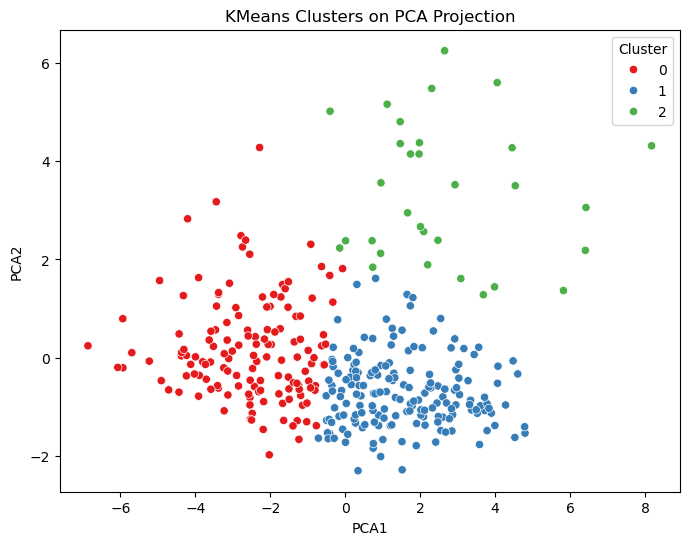

In [15]:
# Plotting for sanity check
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=master,
    x="PCA1",
    y="PCA2",
    hue = "Clusters on PCA", palette = 'Set1'
)

plt.title("KMeans Clusters on PCA Projection")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend(title="Cluster")
plt.show()

C:\Users\vikra\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


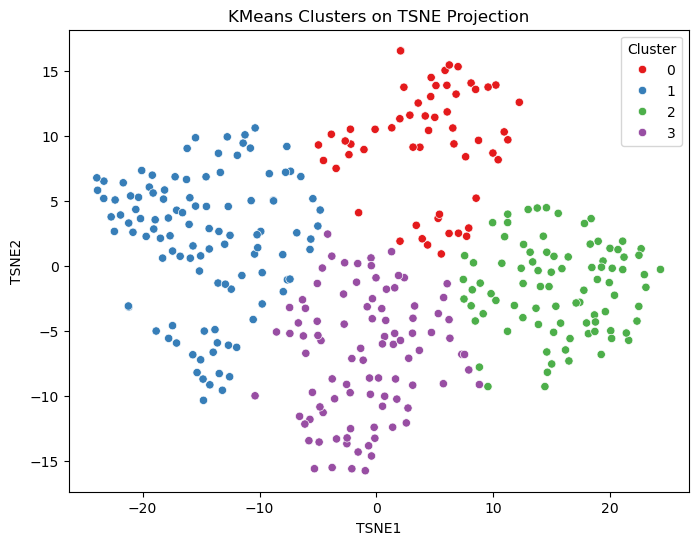

In [16]:
# similarly fot t-SNE
X =master[["TSNE1", "TSNE2"]]
# KMeans with 3 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
master["Clustering on TSNE"] = kmeans.fit_predict(X)

# Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=master,
    x="TSNE1",
    y="TSNE2",
    hue="Clustering on TSNE",
    palette="Set1"
)

plt.title("KMeans Clusters on TSNE Projection")
plt.xlabel("TSNE1")
plt.ylabel("TSNE2")
plt.legend(title="Cluster")
plt.show()

---
## 9. Exporting results (Tableau Ready Datasets)
This section selects the final columns needed for the Tableau dashboard and exports them as CSV files.

Two output files are created:

final_master_tableau.csv: the main analytical dataset containing geographic identifiers, engineered socio-economic features, health values, projection coordinates and Bayesian uncertainty columns.
final_projection.csv: a smaller projection-focused dataset containing PCA/t-SNE coordinates and uncertainty values for the projection dashboard.
These files were used as the final data sources in Tableau.

In [61]:
# Select the main Tableau dataset.
# This contains geographic identifiers, engineered features, projections and Bayesian outputs.
final_master = master[[
    "area_code",
    "geography",
    "rural_urban",

    "pct_healthy_2011",
    "pct_unhealthy_2011",
    "health_index_2011",

    "employment_rate_2011",
    "inactivity_rate_2011",
    "pct_full_time_2011",
    "pct_self_employed_2011",

    "ownership_rate_2011",
    "private_rent_rate_2011",

    "pct_no_qualification_2011",
    "pct_highly_educated_2011",

    "pct_unhealthy_2021",

    "PCA1",
    "PCA2",
    "TSNE1",
    "TSNE2",

    "predicted_unhealthy_2021",
    "lower_credible",
    "upper_credible",
    "Clusters on PCA",
    "Clustering on TSNE"
]]

# Select a smaller projection-focused dataset for Tableau projection views.
final_projection = master[[
    "area_code",
    "geography",
    "rural_urban",
    "PCA1",
    "PCA2",
    "TSNE1",
    "TSNE2",
    "pct_unhealthy_2021",
    "predicted_unhealthy_2021",
    "lower_credible",
    "upper_credible",
    "Clusters on PCA",
    "Clustering on TSNE"
]]

# Export final datasets as CSV files.
final_master.to_csv("final_master_tableau.csv", index=False)
final_projection.to_csv("final_projection.csv", index=False)

# Confirm exported dataset sizes.
print("Saved final_master_tableau.csv")
print("Saved final_projection.csv")
print(final_master.shape)
print(final_projection.shape)

Saved final_master_tableau.csv
Saved final_projection.csv
(348, 24)
(348, 13)


---

**Note on input files and Tableau sources**

The 2011 Census files imported in this notebook are the original official Census/Nomis files used for the Python analytical pipeline. They are used here for merging, feature engineering, projection generation, Bayesian modelling, and creating the final master/projection CSV files.

For the Tableau dashboard, pivoted versions of these same original Census files were prepared separately outside this notebook. The pivoted format was used in Tableau because it was more suitable for visualisation and data relationships.

The final submission includes the original Census files, the pivoted Tableau-ready versions, and the final exported master/projection files.